# Activity 3.2.4 Applying non-parametric tests to a data set

## Scenario
As a data scientist working for an online retail brand, you have been tasked with comparing the customer engagement levels of two new marketing campaigns: Campaign A and Campaign B. To accomplish this, the brand has provided a data set containing engagement scores for each campaign. Your goal is to determine if there is a significant difference in engagement scores between Campaign A and Campaign B.


## Objective
The goal is to compare the effectiveness of two distinct marketing campaigns. The key metric for comparison is the 'Engagement Score', which reflects customer engagement levels with each campaign.

## Assignment criterion
By completing this activity, you will be able to provide evidence that you can demonstrate how to accurately apply parametric and non-parametric methods to analyse diverse data sets.

## Activity guidance
1. Import the necessary libraries and load the data set.
2. Perform an exploratory data analysis to get insights into the data's distribution and potential outliers.
3. Check the distribution of the data using a Shapiro-Wilk test.
4. Formulate a hypothesis to test.
5. Select an appropriate non-parametric test and apply it to the data set to determine if there's a significant difference in engagement between the campaigns.
6. Summarise and interpret your findings. What do the results reveal about the data set and your hypothesis?
6. Reflect critically about the implications of your findings.


> Start your activity here. Select the pen from the toolbar to add your entry.

In [32]:
# Import the necessary libraries.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, shapiro

# Load the dataset.
data = pd.read_csv('<path-to-dataset>/marketing_campaign_data.csv')
data.head()

,Campaign,Engagement Score
0,A,59.393215
1,A,74.367043
2,A,64.248704
3,A,59.039486
4,A,48.128932


# **Descriptive Statistics**

In [33]:
# Descriptive statistics
data.describe(include='all')

,Campaign,Engagement Score
count,200,200.000000
unique,2,NaN
top,A,NaN
freq,100,NaN
mean,NaN,53.578789
std,NaN,23.575596
min,NaN,10.422593
25%,NaN,33.452855
50%,NaN,57.641549
75%,NaN,70.194016


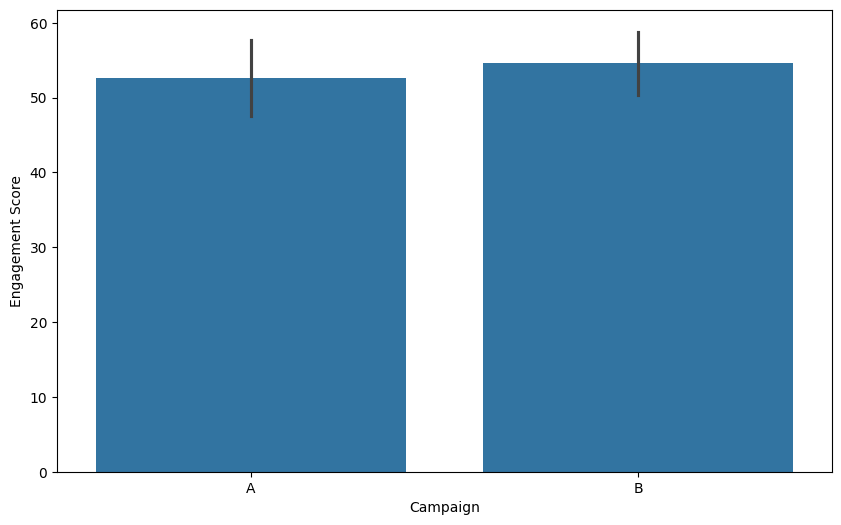

In [30]:
# Stacked Bar Chart

plt.figure(figsize=(10, 6))
sns.barplot(data=data, x='Campaign', y='Engagement Score')
plt.show()

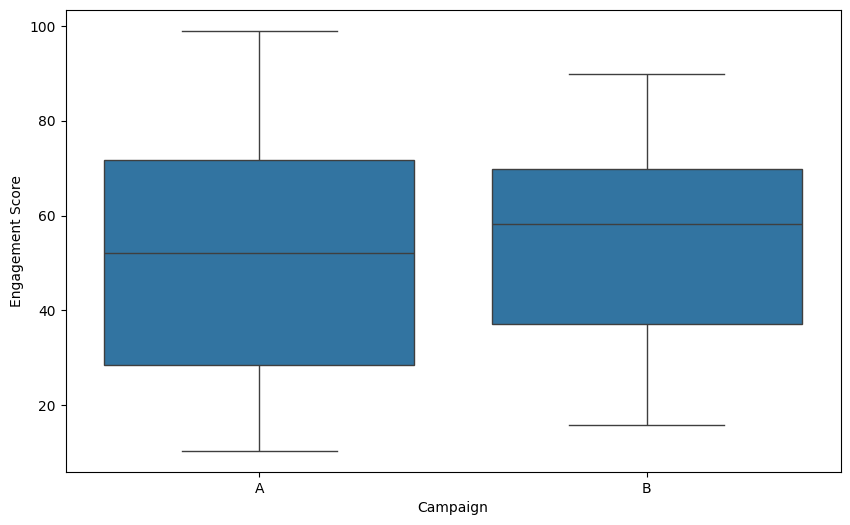

In [29]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='Campaign', y='Engagement Score')
plt.show()

# **Parametrics VS Non-Parametrics**

<function matplotlib.pyplot.show(close=None, block=None)>

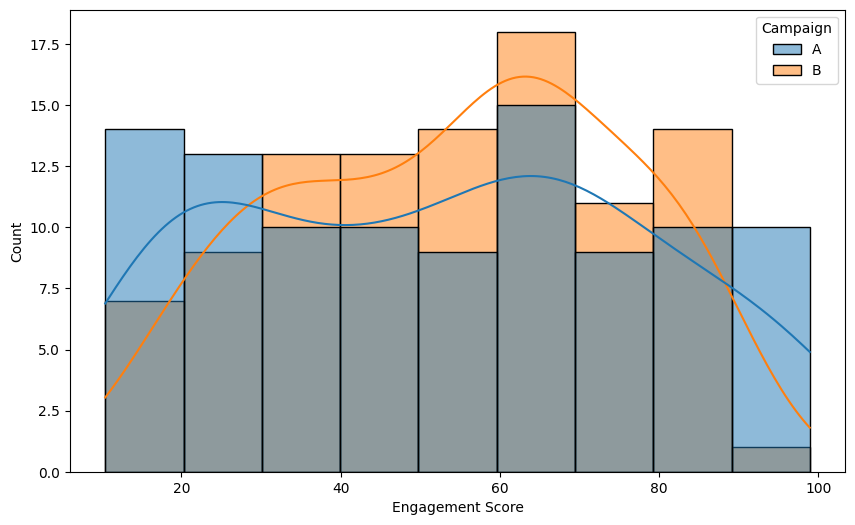

In [28]:
# Histograms

plt.figure(figsize=(10, 6))
sns.histplot(data=data, x='Engagement Score', hue='Campaign', kde=True)
plt.show

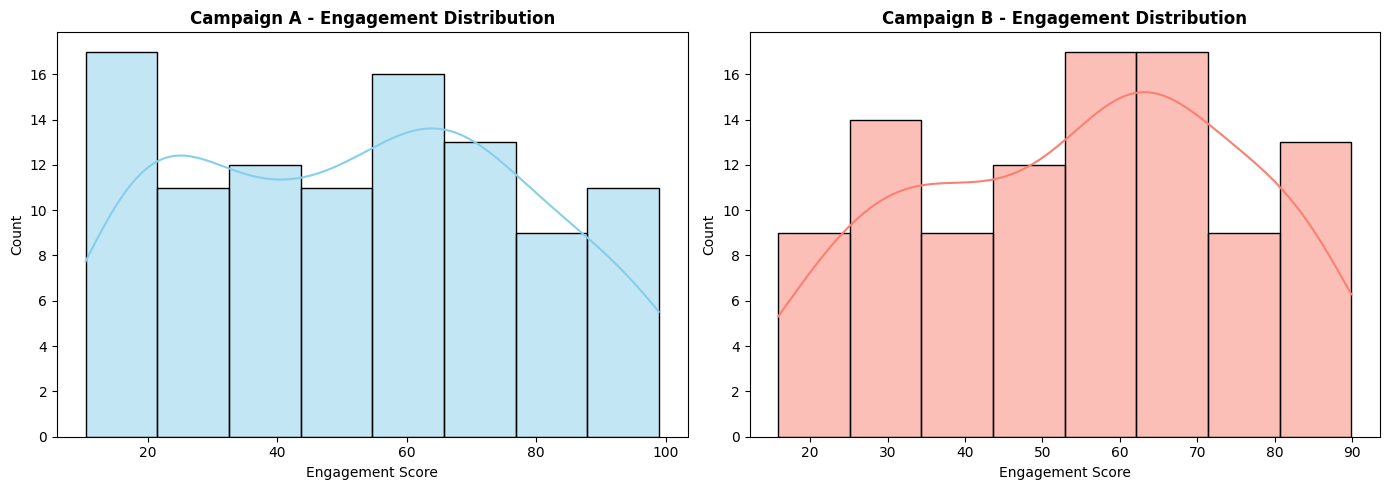

In [27]:
# Create two separate histograms side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Campaign A
sns.histplot(data=data[data['Campaign'] == 'A'], x='Engagement Score',
             kde=True, color='skyblue', ax=ax1)
ax1.set_title('Campaign A - Engagement Distribution', fontweight='bold')

# Campaign B
sns.histplot(data=data[data['Campaign'] == 'B'], x='Engagement Score',
             kde=True, color='salmon', ax=ax2)
ax2.set_title('Campaign B - Engagement Distribution', fontweight='bold')

plt.tight_layout()
plt.show()

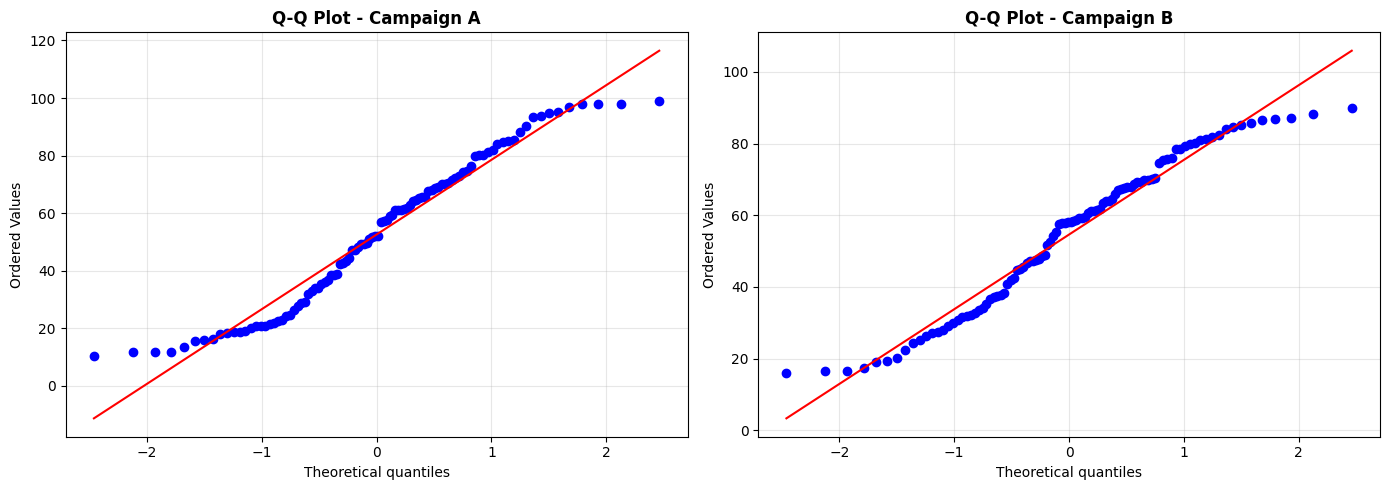

In [26]:
# Q-Q plot
from scipy import stats
campaign_a_data = data[data['Campaign'] == 'A']
campaign_b_data = data[data['Campaign'] == 'B']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Campaign A Q-Q plot
campaign_a = data[data['Campaign'] == 'A']['Engagement Score']
stats.probplot(campaign_a, dist="norm", plot=ax1)  # Changed stat to stats
ax1.set_title('Q-Q Plot - Campaign A', fontweight='bold', fontsize=12)
ax1.grid(alpha=0.3)

# Campaign B Q-Q plot
campaign_b = data[data['Campaign'] == 'B']['Engagement Score']
stats.probplot(campaign_b, dist="norm", plot=ax2)  # Changed stat to stats
ax2.set_title('Q-Q Plot - Campaign B', fontweight='bold', fontsize=12)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# **Shapiro-Wilk Test**

In [14]:
# Shapiro-Wilk test campaign A

campaign_a_data = data[data['Campaign'] == 'A']
campaign_b_data = data[data['Campaign'] == 'B']

stat, p = shapiro(marketing_campaign_a_data['Engagement Score'])
print("Shapiro-Wilk Test - Campaign A", stat)
print("Shapiro-Wilk p-value", p)

alpha = 0.05
if p > alpha:
  print("Sample looks normally distributed (fail to reject H0)")
else:
  print("Sample does not look normally distributed (reject H0)")

Shapiro-Wilk Test - Campaign A 0.9510603435816445
Shapiro-Wilk p-value 0.0009749754084064827
Sample does not look normally distributed (reject H0)


In [15]:
# Shapiro-Wilk test campaign B

campaign_a_data = data[data['Campaign'] == 'A']
campaign_b_data = data[data['Campaign'] == 'B']

stat, p = shapiro(marketing_campaign_b_data['Engagement Score'])
print("Shapiro-Wilk Test - Campaign B", stat)
print("Shapiro-Wilk p-value", p)

alpha = 0.05
if p > alpha:
  print("Sample looks normally distributed (fail to reject H0)")
else:
  print("Sample does not look normally distributed (reject H0)")

Shapiro-Wilk Test - Campaign B 0.958954389888712
Shapiro-Wilk p-value 0.0033892946595134553
Sample does not look normally distributed (reject H0)


# **Hypothesis tests:**

Null Hypothesis (H0): There is no significant difference in engagement scores between Campaign A and Campaign B.
Alternative Hypothesis (H1): There is a significant difference in engagement scores between Campaign A and Campaign B.

The Sapiro-Wilk test for both campaign versiobns A and B indicated the data is not normally distributated. In that case the Mann-Whitney U Test is more appropriate to run the test analysis.



In [20]:
#Mann-Whitney U Test
from scipy.stats import mannwhitneyu
stat, p = mannwhitneyu(marketing_campaign_a_data['Engagement Score'], marketing_campaign_b_data['Engagement Score'])

print(f'Mann-Whitney U Stats: {stat:.3f}')
print(f'P-value: {p:.3f}')

alpha = 0.05
if p > alpha:
	print('Reject the null hypothesis. There is no significant difference in engagement scores between Campaign A and Campaign B.')
else:
	print('Fail to reject the null hypothesis. There is a significant difference in engagement scores between Campaign A and Campaign B.')

Mann-Whitney U Stats: 4741.000
P-value: 0.528
Reject the null hypothesis. There is no significant difference in engagement scores between Campaign A and Campaign B.


# **Summary of Results**

The Mann-Whitney U tests indicates there is no significance in engagement between the campaign A and B.